# Jordan Tourism Site Visits: 2024 vs 2025

**Objective:** Compare recorded visits across 30 tourist and archaeological sites in Jordan, identify the most visited sites and largest percentage changes, and compare foreign and Jordanian visits.

**Tools:** Python, pandas, and Matplotlib.

**Source:** Jordan Ministry of Tourism and Antiquities, `5.2_sites_12-2025.xlsx`, covering January–December 2024 and 2025.

**Data preparation:** Removed report headings, selected and renamed columns, converted visitor counts to integers, and checked missing values, duplicate locations, and totals.

**Scope:** The figures represent recorded site visits, not unique tourists, and cover only the 30 listed sites.

In [59]:
import pandas as pd
df=pd.read_excel("/content/5.2_sites_12-2025.xlsx",header=None)

In [60]:

df.head(10)


,0,1,2,3,4,5,6,7,8,9,10,11
0,NaN,زوار المواقع الاثرية خلال الفترة كانون الثان...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,Number of Visitors to Touristic Sites by Loca...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,الموقع,2024,NaN,NaN,2025,NaN,NaN,التغير النسبي,NaN,NaN,Location
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Relative Change,NaN,NaN,NaN
5,NaN,NaN,أجنبي,أردني,المجموع,أجنبي,أردني,المجموع,أجنبي,أردني,المجموع,NaN
6,NaN,NaN,Foreign,Jordanian,Total,Foreign,Jordanian,Total,Foreign,Jordanian,Total,NaN
7,NaN,البتراء,300581,156634,457215,421128,161422,582550,0.401047,0.030568,0.274127,Petra
8,NaN,جرش,121652,51330,172982,159899,62969,222868,0.314397,0.226748,0.288388,Jarash
9,NaN,ام قيس,17212,63291,80503,24788,92122,116910,0.440158,0.455531,0.452244,Um Qais


In [61]:
df_clean=df.iloc[7:].copy()
df_clean.head(10)

,0,1,2,3,4,5,6,7,8,9,10,11
7,NaN,البتراء,300581,156634,457215,421128,161422,582550,0.401047,0.030568,0.274127,Petra
8,NaN,جرش,121652,51330,172982,159899,62969,222868,0.314397,0.226748,0.288388,Jarash
9,NaN,ام قيس,17212,63291,80503,24788,92122,116910,0.440158,0.455531,0.452244,Um Qais
10,NaN,جبل نيبو,163830,35154,198984,219796,41753,261549,0.34161,0.187717,0.314422,Mount Nebo
11,NaN,قلعة عجلون,101349,249699,351048,93482,243077,336559,-0.077623,-0.02652,-0.041274,Ajlun
12,NaN,مادبا الخارطة,95594,19425,115019,150324,19898,170222,0.572525,0.02435,0.479947,Madaba (Map)
13,NaN,وادي رم,130553,69495,200048,153852,72032,225884,0.178464,0.036506,0.129149,Wadi Rum
14,NaN,قلعة الكرك,38174,32464,70638,44032,30077,74109,0.153455,-0.073528,0.049138,Karak
15,NaN,المغطس,67198,10480,77678,98794,12851,111645,0.470193,0.22624,0.43728,Maghtas
16,NaN,القصور الصحراوية,18989,4850,23839,15737,4015,19752,-0.171257,-0.172165,-0.171442,Desrt Castle


In [62]:
new_names = {
    11: "location",
    2: "foreign_2024",
    3: "jordanian_2024",
    4: "total_2024",
    5: "foreign_2025",
    6: "jordanian_2025",
    7: "total_2025"
}
df_clean.rename(columns=new_names, inplace=True)
df_clean.head(10)

,0,1,foreign_2024,jordanian_2024,total_2024,foreign_2025,jordanian_2025,total_2025,8,9,10,location
7,NaN,البتراء,300581,156634,457215,421128,161422,582550,0.401047,0.030568,0.274127,Petra
8,NaN,جرش,121652,51330,172982,159899,62969,222868,0.314397,0.226748,0.288388,Jarash
9,NaN,ام قيس,17212,63291,80503,24788,92122,116910,0.440158,0.455531,0.452244,Um Qais
10,NaN,جبل نيبو,163830,35154,198984,219796,41753,261549,0.34161,0.187717,0.314422,Mount Nebo
11,NaN,قلعة عجلون,101349,249699,351048,93482,243077,336559,-0.077623,-0.02652,-0.041274,Ajlun
12,NaN,مادبا الخارطة,95594,19425,115019,150324,19898,170222,0.572525,0.02435,0.479947,Madaba (Map)
13,NaN,وادي رم,130553,69495,200048,153852,72032,225884,0.178464,0.036506,0.129149,Wadi Rum
14,NaN,قلعة الكرك,38174,32464,70638,44032,30077,74109,0.153455,-0.073528,0.049138,Karak
15,NaN,المغطس,67198,10480,77678,98794,12851,111645,0.470193,0.22624,0.43728,Maghtas
16,NaN,القصور الصحراوية,18989,4850,23839,15737,4015,19752,-0.171257,-0.172165,-0.171442,Desrt Castle


In [63]:
df_clean=df_clean[["location","foreign_2024","jordanian_2024","total_2024","foreign_2025","jordanian_2025","total_2025"]].copy()

In [64]:
df_clean.columns

Index(['location', 'foreign_2024', 'jordanian_2024', 'total_2024',
       'foreign_2025', 'jordanian_2025', 'total_2025'],
      dtype='object')

In [65]:
df_clean.head()

,location,foreign_2024,jordanian_2024,total_2024,foreign_2025,jordanian_2025,total_2025
7,Petra,300581,156634,457215,421128,161422,582550
8,Jarash,121652,51330,172982,159899,62969,222868
9,Um Qais,17212,63291,80503,24788,92122,116910
10,Mount Nebo,163830,35154,198984,219796,41753,261549
11,Ajlun,101349,249699,351048,93482,243077,336559


In [66]:
df_clean.shape

(30, 7)

In [67]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 7 to 36
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   location        30 non-null     object
 1   foreign_2024    30 non-null     object
 2   jordanian_2024  30 non-null     object
 3   total_2024      30 non-null     object
 4   foreign_2025    30 non-null     object
 5   jordanian_2025  30 non-null     object
 6   total_2025      30 non-null     object
dtypes: object(7)
memory usage: 1.8+ KB


In [68]:
df_clean.isnull().sum()

,0
location,0
foreign_2024,0
jordanian_2024,0
total_2024,0
foreign_2025,0
jordanian_2025,0
total_2025,0


In [69]:
df_clean['foreign_2024']=df_clean['foreign_2024'].astype(int)
df_clean['jordanian_2024']=df_clean['jordanian_2024'].astype(int)
df_clean['total_2024']=df_clean['total_2024'].astype(int)
df_clean['foreign_2025']=df_clean['foreign_2025'].astype(int)
df_clean['jordanian_2025']=df_clean['jordanian_2025'].astype(int)
df_clean['total_2025']=df_clean['total_2025'].astype(int)

In [70]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 7 to 36
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   location        30 non-null     object
 1   foreign_2024    30 non-null     int64 
 2   jordanian_2024  30 non-null     int64 
 3   total_2024      30 non-null     int64 
 4   foreign_2025    30 non-null     int64 
 5   jordanian_2025  30 non-null     int64 
 6   total_2025      30 non-null     int64 
dtypes: int64(6), object(1)
memory usage: 1.8+ KB


In [71]:
df_clean["location"].duplicated().sum()

np.int64(0)

In [72]:
top5_2025=df_clean[["location","total_2025"]]
top5_2025=top5_2025.sort_values(by="total_2025",ascending=False)
top5_2025=top5_2025.head(5)

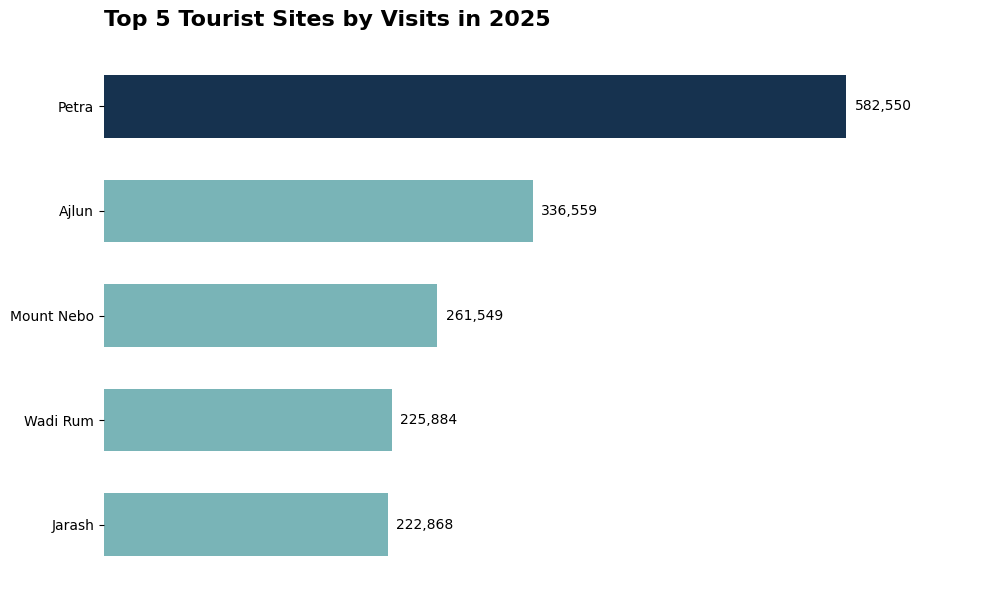

In [90]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10,6))
colors = ["#16324F", "#79B4B7", "#79B4B7", "#79B4B7", "#79B4B7"]
bars = plt.barh(top5_2025["location"], top5_2025["total_2025"], color=colors, height=0.6)
plt.bar_label(bars, fmt="{:,.0f}", padding=6)
plt.gca().invert_yaxis()
plt.xlim(0, top5_2025["total_2025"].max() * 1.18)
plt.xlabel("")
plt.ylabel("")
plt.xticks([])
plt.title("Top 5 Tourist Sites by Visits in 2025", fontsize=16, fontweight="bold", loc="left", pad=18)
plt.box(False)
plt.savefig("top5_sites_2025.png", dpi=300,bbox_inches="tight", facecolor="white")
plt.tight_layout()


In [74]:
df_clean=df_clean.reset_index(drop=True)
df_clean["visit_change"]=df_clean['total_2025']-df_clean["total_2024"]
df_clean[["location","total_2024","total_2025","visit_change"]]


,location,total_2024,total_2025,visit_change
0,Petra,457215,582550,125335
1,Jarash,172982,222868,49886
2,Um Qais,80503,116910,36407
3,Mount Nebo,198984,261549,62565
4,Ajlun,351048,336559,-14489
5,Madaba (Map),115019,170222,55203
6,Wadi Rum,200048,225884,25836
7,Karak,70638,74109,3471
8,Maghtas,77678,111645,33967
9,Desrt Castle,23839,19752,-4087


In [75]:
(df_clean['total_2024']==0).sum()

np.int64(0)

In [76]:
df_clean["growth_pct"] = (df_clean["visit_change"] / df_clean["total_2024"] * 100).round(2)
df_clean

,location,foreign_2024,jordanian_2024,total_2024,foreign_2025,jordanian_2025,total_2025,visit_change,growth_pct
0,Petra,300581,156634,457215,421128,161422,582550,125335,27.41
1,Jarash,121652,51330,172982,159899,62969,222868,49886,28.84
2,Um Qais,17212,63291,80503,24788,92122,116910,36407,45.22
3,Mount Nebo,163830,35154,198984,219796,41753,261549,62565,31.44
4,Ajlun,101349,249699,351048,93482,243077,336559,-14489,-4.13
5,Madaba (Map),95594,19425,115019,150324,19898,170222,55203,47.99
6,Wadi Rum,130553,69495,200048,153852,72032,225884,25836,12.91
7,Karak,38174,32464,70638,44032,30077,74109,3471,4.91
8,Maghtas,67198,10480,77678,98794,12851,111645,33967,43.73
9,Desrt Castle,18989,4850,23839,15737,4015,19752,-4087,-17.14


In [77]:
growth_ranked=df_clean[["location","total_2024","total_2025","growth_pct"]]
growth_ranked=growth_ranked.sort_values(by="growth_pct", ascending=False)
growth_ranked.head(10)



,location,total_2024,total_2025,growth_pct
26,Dar Al-Saraya Museum,4523,6976,54.23
5,Madaba (Map),115019,170222,47.99
2,Um Qais,80503,116910,45.22
8,Maghtas,77678,111645,43.73
23,The Cave of Prophet Lot,3297,4443,34.76
17,Madaba Center,103662,137143,32.30
3,Mount Nebo,198984,261549,31.44
1,Jarash,172982,222868,28.84
0,Petra,457215,582550,27.41
27,Machaerus,13167,16207,23.09


In [78]:
growth_ranked.tail(5)

,location,total_2024,total_2025,growth_pct
9,Desrt Castle,23839,19752,-17.14
18,Shobak,13292,10532,-20.76
15,Salt Museum,28755,22485,-21.80
16,Um ALjmal,21176,14633,-30.90
10,Pella,6082,4172,-31.40


In [79]:
growth_extremes=pd.concat([growth_ranked.head(5),growth_ranked.tail(5)])
growth_extremes


,location,total_2024,total_2025,growth_pct
26,Dar Al-Saraya Museum,4523,6976,54.23
5,Madaba (Map),115019,170222,47.99
2,Um Qais,80503,116910,45.22
8,Maghtas,77678,111645,43.73
23,The Cave of Prophet Lot,3297,4443,34.76
9,Desrt Castle,23839,19752,-17.14
18,Shobak,13292,10532,-20.76
15,Salt Museum,28755,22485,-21.80
16,Um ALjmal,21176,14633,-30.90
10,Pella,6082,4172,-31.40


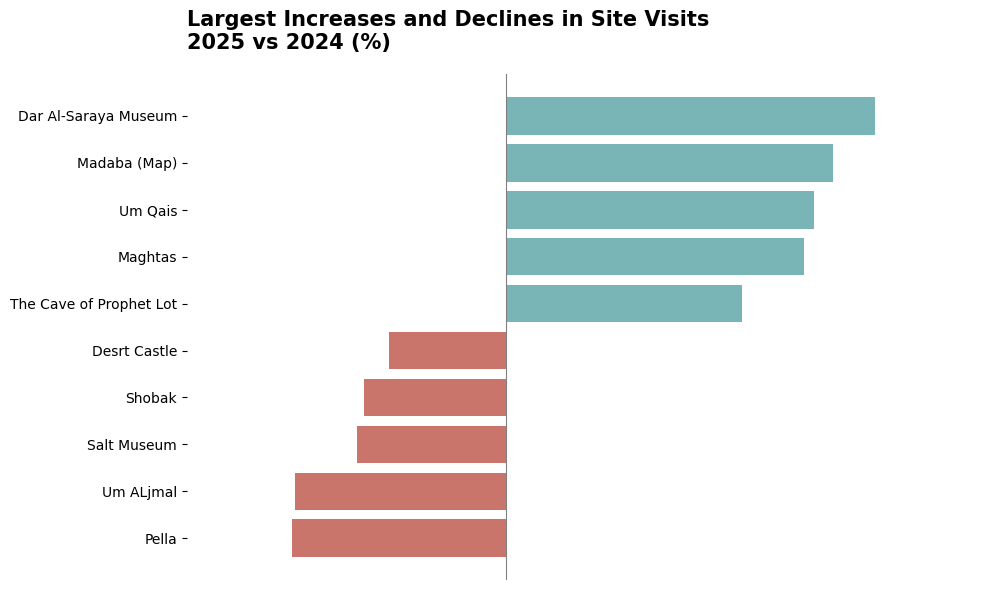

In [94]:
y=growth_extremes["growth_pct"]
x=growth_extremes["location"]
colors = ["#79B4B7"] * 5 + ["#C9756B"] * 5
plt.figure(figsize=(10,6))
plt.gca().invert_yaxis()
plt.bar_label(bars, fmt="{:+.2f}%", padding=6)
plt.axvline(0, color="gray", linewidth=0.8)
bars=plt.barh(x,y,color=colors)
plt.title(
    "Largest Increases and Declines in Site Visits\n2025 vs 2024 (%)",
    fontsize=15,
    fontweight="bold",
    loc="left",
    pad=18
)
plt.xticks([])
plt.xlabel("")
plt.ylabel("")
plt.box(False)
plt.margins(x=0.18)
plt.savefig("site_growth_2024_2025.png", dpi=300,bbox_inches="tight", facecolor="white")
plt.tight_layout()




In [81]:
foreign_2024_total = df_clean["foreign_2024"].sum()
foreign_2025_total = df_clean["foreign_2025"].sum()
jordanian_2024_total = df_clean["jordanian_2024"].sum()
jordanian_2025_total = df_clean["jordanian_2025"].sum()


In [82]:
comparison = pd.DataFrame({
    "year": [2024, 2025],
    "Foreign": [foreign_2024_total, foreign_2025_total],
    "Jordanian": [jordanian_2024_total, jordanian_2025_total]
})
comparison

,year,Foreign,Jordanian
0,2024,1408683,1178417
1,2025,1795236,1195433


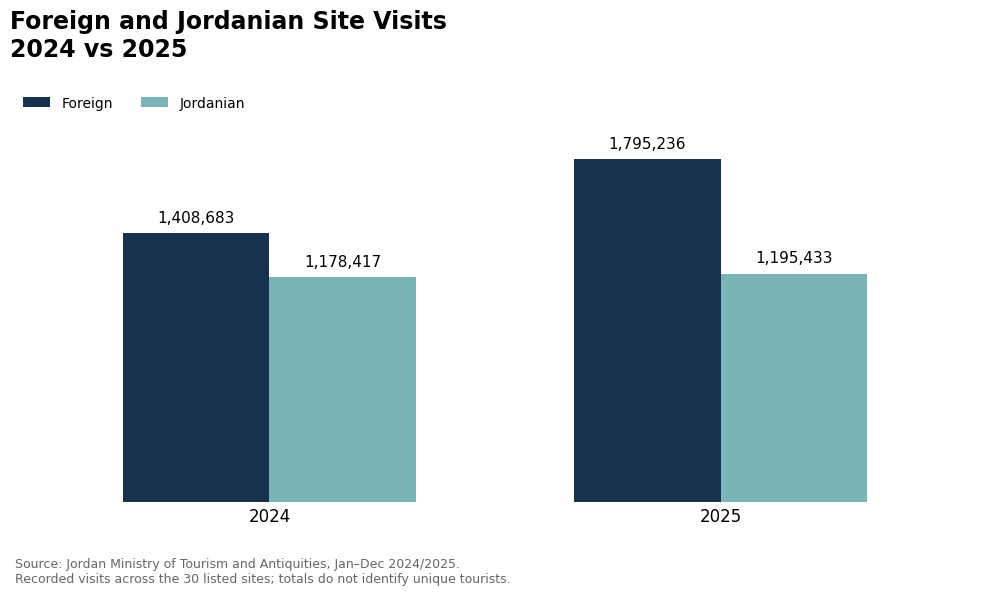

In [91]:
from google.colab import files

ax = comparison.plot.bar(x="year", y=["Foreign", "Jordanian"], color=["#16324F", "#79B4B7"],
    figsize=(10, 6), width=0.65, rot=0)
for bars in ax.containers:
    ax.bar_label(bars, fmt="{:,.0f}", padding=6, fontsize=11)
ax.set_title("Foreign and Jordanian Site Visits\n2024 vs 2025", fontsize=17, fontweight="bold",
    loc="left", pad=20)
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_yticks([])
ax.tick_params(axis="x", length=0, labelsize=12)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.legend(frameon=False, loc="upper left", ncol=2)
largest_total = comparison[["Foreign", "Jordanian"]].max().max()
ax.set_ylim(0, largest_total * 1.22)
ax.figure.text(
    0.02, 0.02,
    "Source: Jordan Ministry of Tourism and Antiquities, Jan–Dec 2024/2025.\n"
    "Recorded visits across the 30 listed sites; totals do not identify unique tourists.",
    fontsize=9,
    color="#666666"
)

plt.savefig("foreign_jordanian_comparison.png", dpi=300,bbox_inches="tight", facecolor="white")
ax.figure.tight_layout(rect=[0, 0.09, 1, 1])






In [93]:
from google.colab import files

files.download("top5_sites_2025.png")
files.download("site_growth_2024_2025.png")
files.download("foreign_jordanian_comparison.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [84]:
(
    df_clean["foreign_2024"] + df_clean["jordanian_2024"]
    == df_clean["total_2024"]
).all()

np.False_

In [85]:
mismatch_2024 = (
    df_clean["foreign_2024"] + df_clean["jordanian_2024"]
    != df_clean["total_2024"]
)

df_clean.loc[
    mismatch_2024,
    ["location", "foreign_2024", "jordanian_2024", "total_2024"]
]

,location,foreign_2024,jordanian_2024,total_2024
25,Hammamat Ma'in,12662,50476,63502


In [86]:
(
    df_clean["foreign_2025"] + df_clean["jordanian_2025"]
    == df_clean["total_2025"]
).all()

np.True_



1. **Petra recorded the most visits in 2025.** Among the 30 sites in the dataset, Petra ranked first with **582,550 visits**, an increase of **27.41%** from 2024.

2. **Dar Al-Saraya Museum had the highest percentage growth.** Visits increased from **4,523 in 2024 to 6,976 in 2025**, a rise of **54.23%**. However, this represents **2,453 additional visits**, compared with Petra’s **125,335 additional visits**. This shows why percentage growth and absolute change should be considered together.

3. **Pella experienced the largest percentage decline.** Total visits fell from **6,082 to 4,172**, a decrease of **31.40%**. Jordanian visits dropped from **2,962 to 800**, while foreign visits increased from **3,120 to 3,372**. The fall in Jordanian visits therefore accounted for the overall decline, partly offset by increased foreign visits. Further research would be needed to explain this change.


4. **Foreign site visits grew faster than Jordanian site visits.** Across the 30
listed sites, foreign visits increased from **1,408,683 in 2024 to 1,795,236 in 2025**, a rise of **27.44%**. Jordanian visits increased more modestly, from **1,178,417 to 1,195,433**, or **1.44%**. Foreign visits therefore accounted for most of the overall increase in recorded visits across these sites.

5. **Data quality note**

One inconsistency was found in Hammamat Ma’in’s 2024 figures: foreign and Jordanian visits sum to **63,138**, while the published total is **63,502**, a difference of **364 visits**. All 2025 rows passed the same check. The published values were retained because the correct figure could not be verified.





